# 04 · Chemistry of the activation clusters

Each cluster against all other clustered odorants: Fisher's exact test for functional groups,
Cliff's delta with Mann-Whitney for descriptors, Benjamini-Hochberg over each grid. The
principal coordinates of the Jaccard distances place the odorants for display.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Downstream_Analysis/scripts"))
sys.path.append(str(REPO / "scripts"))
import matplotlib.pyplot as plt
import activation_code as ac
import activation_figures as af
from plotting_functions import custom_plots

plt.rcParams.update(custom_plots())

PROBABILITIES = REPO / "Downstream_Analysis/predictions/aggregated/Reference_Tree_Predictions/reference_median_probability_wide.csv"
M2OR_PAIRS = REPO / "Model_Inputs/Data_Preparation/processed/m2or_pairs_model.csv"
ODOURS = REPO / "Chemicals/processed_data/m2or_inchi_odors_smiles.csv"
FASTA = REPO / "Phylogenetic_Analysis/data/ReferenceTree/PF13853.9606_7955_7740_7764_75743_137246.fa"
CLASSES = REPO / "Phylogenetic_Analysis/data/HumanTree/human433_OR_classes.csv"
TABLES = Path("results")
TABLES.mkdir(exist_ok=True)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

In [2]:
hybrid_table = pd.read_csv(TABLES / "hybrid_matrix.csv", index_col=0)
receptor_ids = list(hybrid_table.index)
odorant_ids = list(hybrid_table.columns)
hybrid = hybrid_table.values
clusters = pd.read_csv(TABLES / "odorant_clusters.csv")
info, display_order = ac.clusters_from_table(clusters)
clustered_ids = clusters.smiles_id.values
labels = clusters.cluster.values
smiles_by_odorant, tags_by_odorant = ac.odour_tags(M2OR_PAIRS, ODOURS, odorant_ids)

In [3]:
cluster_odorants = ac.odorant_descriptors(clustered_ids, smiles_by_odorant, labels)
cluster_odorants["cluster_tag"] = cluster_odorants.cluster.map(dict(zip(clusters.cluster, clusters.cluster_tag)))
cluster_odorants.to_csv(TABLES / "cluster_odorants.csv", index=False)

group_tests = ac.cluster_group_tests(cluster_odorants, display_order)
group_tests.to_csv(TABLES / "cluster_functional_groups.csv", index=False)
descriptor_effects = ac.cluster_descriptor_effects(cluster_odorants, display_order)
descriptor_effects.to_csv(TABLES / "cluster_descriptor_effects.csv", index=False)
print(f"functional-group tests {len(group_tests)}, q < 0.05: {(group_tests.q < 0.05).sum()}")

functional-group tests 54, q < 0.05: 18


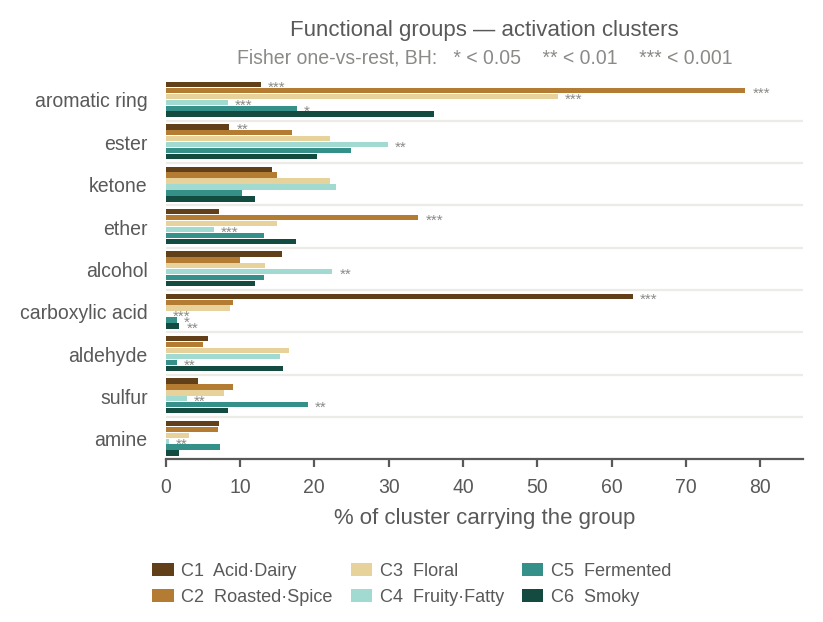

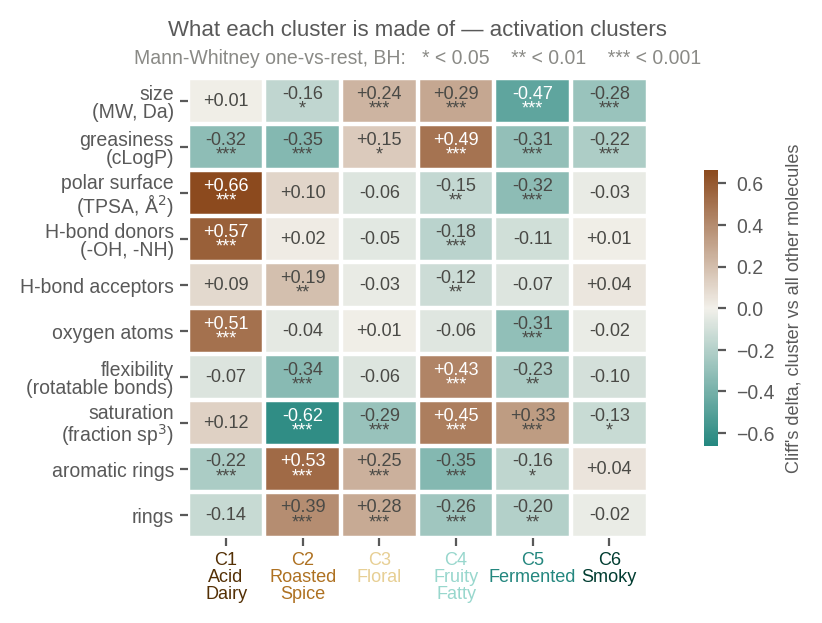

In [4]:
# Functional groups and descriptors per cluster (Extended Data Fig. 4b, c).
af.cluster_functional_groups(pd.read_csv(TABLES / "cluster_functional_groups.csv"), info, display_order,
                             "activation clusters", FIGURES / "cluster_functional_groups.svg", show=True)
af.cluster_effects(pd.read_csv(TABLES / "cluster_descriptor_effects.csv"), info, display_order,
                   "activation clusters", FIGURES / "cluster_descriptor_effects.svg", show=True)

In [5]:
clustered_matrix = hybrid[:, [odorant_ids.index(o) for o in clustered_ids]]
coordinates, variance = ac.cluster_pcoa(clustered_ids, clustered_matrix, labels)
coordinates.to_csv(TABLES / "cluster_pcoa.csv", index=False)
variance.to_csv(TABLES / "cluster_pcoa_variance.csv", index=False)
variance.round(1)

,pco1_percent,pco2_percent,negative_percent
0,16.0,10.9,8.5


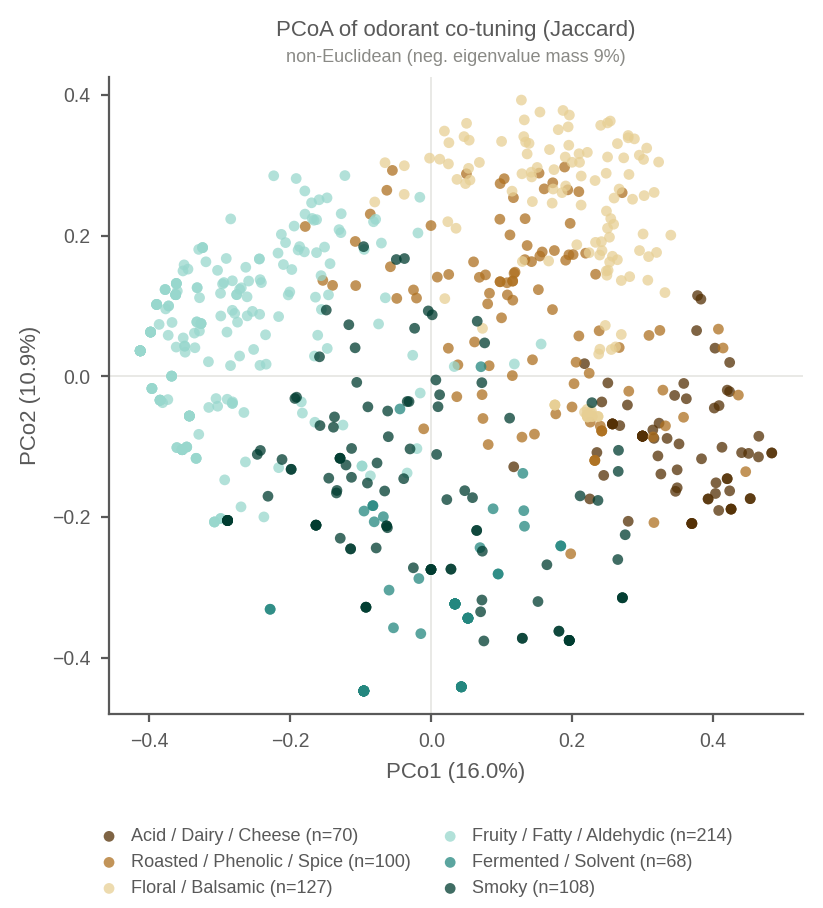

In [6]:
# Principal coordinates of the Jaccard distances (Extended Data Fig. 4a).
af.pcoa_figure(pd.read_csv(TABLES / "cluster_pcoa.csv"), pd.read_csv(TABLES / "cluster_pcoa_variance.csv"),
               info, display_order, "PCoA of odorant co-tuning (Jaccard)", FIGURES / "cluster_pcoa.svg", show=True)

In [7]:
summary = af.cluster_summary(cluster_odorants, info, display_order)
summary.to_csv(TABLES / "cluster_summary.csv", index=False)

enrichment = pd.read_csv(TABLES / "cluster_tag_enrichment.csv")
table1 = ac.table_one(summary, enrichment, group_tests, display_order)
table1.to_csv(TABLES / "table1_clusters.csv", index=False)
table1

,cluster,subject,n,top descriptors,enriched functional groups,MW,cLogP,TPSA,Fsp3
0,C1,Acid / Dairy / Cheese,70,"acidic (13.2, q = 6e-06); sour (11.6, q = 7e-1...","carboxylic acid, 63 vs 4% (q = 2e-32)",159,1.8,37,0.80
1,C2,Roasted / Phenolic / Spice,100,"hazelnut (4.0, q = 0.03); warm (3.9, q = 0.02)...","aromatic ring, 78 vs 25% (q = 7e-23); ether, 3...",150,1.9,26,0.29
2,C3,Floral / Balsamic,127,"floral (1.7, q = 0.0008)","aromatic ring, 53 vs 28% (q = 2e-06)",170,2.6,20,0.50
3,C4,Fruity / Fatty / Aldehydic,214,"cucumber (2.6, q = 0.01); coconut (2.4, q = 0....","alcohol, 22 vs 13% (q = 0.007); ester, 30 vs 1...",168,3.0,20,0.83
4,C5,Fermented / Solvent,68,"solvent (6.4, q = 0.003); alcoholic (5.3, q = ...","sulfur, 19 vs 6% (q = 0.003)",130,1.7,20,0.86
5,C6,Smoky,108,"smoky (4.0, q = 0.003); medicinal (2.9, q = 0....",none,138,2.0,20,0.59
